# 02 Align: FPFH + RANSAC + ICP against PC2Model ground truth, and the scale problem

**Slice.** Two PC2Model samples. `real-indoor_modelling_3-ISPRS_indoor_modelling-UVigo` is a real indoor
scan (one scanner position, 9.5M points; the model is an 80k-triangle OBJ) at scale 1. `fur_010-modelnet` is the
smallest sample whose ground-truth transform has scale ≠ 1.

**Question.** Does the classical baseline (voxel downsample, FPFH features, RANSAC global registration, then
point-to-plane ICP) recover PC2Model's ground-truth transform on a real indoor scan, and what does it do when the
scan is at a different scale from the model?

**Reading the numbers.** The ground-truth matrix `T` maps the transformed scan into the model frame (measured below
on UVigo: scan points moved by `T` lie a median 0.042 m from the model, and 927 m with `inv(T)`), so the registration
estimate should approximate `T` itself. The *registration residual* is the distance from the registered scan
points to the model mesh. It is a measure of registration quality, not an accuracy level (see `CONTEXT.md`).

In [1]:
import csv
import resource
import time
from pathlib import Path

import numpy as np
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.load import load_e57
from scan_vs_bim.pc2model import parse_transform, scale_of

reg = o3d.pipelines.registration
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "pc2model"
OUT = ROOT / "outputs" / "02"
OUT.mkdir(parents=True, exist_ok=True)
t_notebook = time.perf_counter()

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# ---- Every knob of this notebook is in this cell. Re-running gives the same numbers. -------------------------

SAMPLES = {
    "UVigo": "real-indoor_modelling_3-ISPRS_indoor_modelling-UVigo",   # scale 1
    "fur_010": "fur_010-modelnet",                                     # scale 1.357, the smallest scaled sample
}

# Seeds. Used for: the model-surface sampling, the scan subsample, and RANSAC (reseeded before every RANSAC run).
SEED = 0

# Point budgets.
MODEL_POINTS = 500_000        # points sampled uniformly from the model mesh surface
MAX_SCAN_POINTS = 1_000_000   # at most this many scan points are loaded (the UVigo scan has 9.5M)

# Voxel size = VOXEL_FRACTION * diagonal of the model's bounding box. The same rule for both samples.
VOXEL_FRACTION = 0.008
VOXEL_SWEEP = [0.006, 0.008, 0.012]   # robustness tables only: every voxel fraction is run
SEED_SWEEP = [0, 1, 2, 3, 4]          # with every one of these seeds

# Feature radii, as multiples of the voxel size.
NORMAL_RADIUS_X, NORMAL_MAX_NN = 2.0, 30
FPFH_RADIUS_X, FPFH_MAX_NN = 5.0, 100

# RANSAC (feature matching): max iterations, confidence, inlier distance (x voxel), edge-length check.
RANSAC_MAX_ITER, RANSAC_CONFIDENCE = 1_000_000, 0.999
RANSAC_DISTANCE_X = 1.5
RANSAC_EDGE_RATIO = 0.9
RANSAC_MUTUAL_FILTER = True

# Point-to-plane ICP: max correspondence distance (x voxel) and iterations.
ICP_DISTANCE_X, ICP_MAX_ITER = 2.0, 100

# Offscreen rendering.
RENDER_SIZE = (800, 533)
RENDER_POINTS = 60_000      # points drawn per cloud
POINT_SIZE = 3.0

# Gate thresholds from docs/roadmap.md (judgement calls, not from a standard). Printed as context only.
GATE_ROT_DEG, GATE_TRANS_M, GATE_SCALE_REL = 2.0, 0.05, 0.01

## The scaled sample

`scripts/find_scaled_sample.py` reads only the 137 transform files of PC2Model over HTTP range requests, computes each
sample's scale (cube root of the determinant of the 3x3 block), writes `outputs/pc2model_scales.csv`, and fetches the
smallest sample whose scale differs from 1. This notebook does not repeat that search; it reads the CSV the script wrote.

In [3]:
csv_path = ROOT / "outputs" / "pc2model_scales.csv"
if not csv_path.exists():
    raise FileNotFoundError("outputs/pc2model_scales.csv is missing. Run: uv run python scripts/find_scaled_sample.py")
rows = list(csv.DictReader(open(csv_path)))
scaled = [r for r in rows if abs(float(r["scale"]) - 1) > 1e-3]
smallest = min(scaled, key=lambda r: float(r["compressed_mb"]))
print(f"{len(rows)} samples in the CSV, {len(scaled)} with scale != 1 (range {min(float(r['scale']) for r in scaled):.2f} "
      f"to {max(float(r['scale']) for r in scaled):.2f}).")
print(f"Smallest scaled sample: {smallest['sample']}, {smallest['compressed_mb']} MB compressed, scale {smallest['scale']}")
assert smallest["sample"].endswith(SAMPLES["fur_010"]), "SAMPLES['fur_010'] is not the smallest scaled sample any more"
for name in SAMPLES.values():
    if not (DATA / name).exists():
        raise FileNotFoundError(f"data/pc2model/{name} is missing. Run: uv run python scripts/find_scaled_sample.py "
                         "(scaled sample) or uv run python scripts/fetch_data.py (UVigo)")

137 samples in the CSV, 71 with scale != 1 (range 0.69 to 1.98).
Smallest scaled sample: PC2Model_v1.4/furniture/fur_010-modelnet, 0.38 MB compressed, scale 1.357291


## The baseline, stage by stage

1. **Model side.** Sample the OBJ surface uniformly into a point cloud, so both sides use the same point-cloud tools.
2. **Scan side.** `load_e57` with a seeded subsample.
3. **Voxel size** = a fixed fraction of the model's bounding-box diagonal (the same rule for both samples).
4. **Normals and FPFH** on the downsampled clouds, with radii that are multiples of the voxel size.
5. **RANSAC** over FPFH correspondences gives a coarse transform. **Point-to-plane ICP** refines it.
6. **Metrics against `T`:** rotation error (geodesic angle between the estimated and true rotation), translation
   error, and the registration residual (distance from every loaded scan point to the model *mesh*, via ray casting).
   The scan is the source and the model the target, so the estimate maps scan to model, like `T`.

The translation error is the difference of the two translation vectors. That vector is where the scan's *origin* lands, and
the scans here sit hundreds of metres from their origin, so a small rotation error is multiplied by that lever arm.
The table therefore also gives the *centroid error*: the distance between where the estimate and `T` put the scan's centroid.

In [4]:
def seed_all(seed=SEED):
    np.random.seed(seed)
    o3d.utility.random.seed(seed)


def load_sample(key):
    d = DATA / SAMPLES[key]
    mesh = o3d.io.read_triangle_mesh(str(next(d.glob("model_*.obj"))))
    T_gt = parse_transform(next(d.glob("transformation_matrix_*.txt")).read_text())
    seed_all()
    model = mesh.sample_points_uniformly(MODEL_POINTS)
    scan = load_e57(next(d.glob("pointcloud_*_transformed.e57")), MAX_SCAN_POINTS, SEED)
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
    diag = float(np.linalg.norm(mesh.get_axis_aligned_bounding_box().get_extent()))
    return dict(key=key, mesh=mesh, model=model, scan=scan, T_gt=T_gt, scene=scene, diag=diag)


def preprocess(pcd, voxel):
    down = pcd.voxel_down_sample(voxel)
    down.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=NORMAL_RADIUS_X * voxel, max_nn=NORMAL_MAX_NN))
    fpfh = reg.compute_fpfh_feature(down, o3d.geometry.KDTreeSearchParamHybrid(radius=FPFH_RADIUS_X * voxel, max_nn=FPFH_MAX_NN))
    return down, fpfh


def register(scan, model, voxel, seed=SEED):
    src, src_f = preprocess(scan, voxel)
    tgt, tgt_f = preprocess(model, voxel)
    seed_all(seed)   # reseeded right before RANSAC, so its result does not depend on what ran before
    ransac = reg.registration_ransac_based_on_feature_matching(
        src, tgt, src_f, tgt_f, RANSAC_MUTUAL_FILTER, RANSAC_DISTANCE_X * voxel,
        reg.TransformationEstimationPointToPoint(False), 3,
        [reg.CorrespondenceCheckerBasedOnEdgeLength(RANSAC_EDGE_RATIO),
         reg.CorrespondenceCheckerBasedOnDistance(RANSAC_DISTANCE_X * voxel)],
        reg.RANSACConvergenceCriteria(RANSAC_MAX_ITER, RANSAC_CONFIDENCE))
    icp = reg.registration_icp(src, tgt, ICP_DISTANCE_X * voxel, ransac.transformation,
                               reg.TransformationEstimationPointToPlane(),
                               reg.ICPConvergenceCriteria(max_iteration=ICP_MAX_ITER))
    return ransac.transformation, icp.transformation, dict(n_src=len(src.points), n_tgt=len(tgt.points),
                                                           ransac_fitness=ransac.fitness, icp_fitness=icp.fitness)


def apply(T, pts):
    return pts @ T[:3, :3].T + T[:3, 3]


def rotation_error_deg(T_est, T_gt):
    # Geodesic angle between the two rotations; the scale is divided out of each 3x3 block first.
    A, B = T_est[:3, :3] / scale_of(T_est), T_gt[:3, :3] / scale_of(T_gt)
    return float(np.degrees(np.arccos(np.clip((np.trace(A.T @ B) - 1) / 2, -1, 1))))


def centroid_error(T_est, s):
    c = np.asarray(s["scan"].points).mean(0)
    return float(np.linalg.norm(apply(T_est, c) - apply(s["T_gt"], c)))


def metrics(T_est, s):
    # Rotation, translation, centroid error against s['T_gt']; residual of the whole loaded scan against the model mesh.
    T_gt, pts = s["T_gt"], np.asarray(s["scan"].points)
    s_est, s_gt = scale_of(T_est), scale_of(T_gt)
    d = s["scene"].compute_distance(o3d.core.Tensor(apply(T_est, pts).astype(np.float32))).numpy()
    return dict(rot_deg=rotation_error_deg(T_est, T_gt),
                trans_m=float(np.linalg.norm(T_est[:3, 3] - T_gt[:3, 3])),
                centroid_m=centroid_error(T_est, s),
                resid_mean=float(d.mean()), resid_median=float(np.median(d)),
                scale=s_est, scale_err=abs(s_est - s_gt) / s_gt)


def table(rows):
    print(f"{'':28s}{'rot err':>9s}{'|dt|':>10s}{'centroid':>10s}{'resid mean':>12s}{'resid med':>11s}{'scale':>8s}{'scale err':>10s}")
    print(f"{'':28s}{'(deg)':>9s}{'(m)':>10s}{'err (m)':>10s}{'(m)':>12s}{'(m)':>11s}{'':>8s}{'(%)':>10s}")
    for name, m in rows:
        print(f"{name:28s}{m['rot_deg']:9.3f}{m['trans_m']:10.3f}{m['centroid_m']:10.3f}{m['resid_mean']:12.3f}"
              f"{m['resid_median']:11.3f}{m['scale']:8.4f}{100 * m['scale_err']:10.2f}")


def gate_line(m, scaled=False):
    ok = lambda b: "within" if b else "outside"
    s = (f"vs the roadmap gate (a judgement call): rotation {ok(m['rot_deg'] <= GATE_ROT_DEG)} {GATE_ROT_DEG} deg, "
         f"centroid error {ok(m['centroid_m'] <= GATE_TRANS_M)} {100 * GATE_TRANS_M:.0f} cm")
    if scaled:
        s += f", scale error {ok(m['scale_err'] <= GATE_SCALE_REL)} {100 * GATE_SCALE_REL:.0f}%"
    return s


def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9   # macOS reports bytes

In [5]:
def render_png(layers, path, eye_dir=(0.0, 0.0, 1.0), up=(0.0, 1.0, 0.0), zmax=None):
    # layers: list of (point cloud, RGB). The camera looks at the union of the clouds from direction eye_dir.
    rng = np.random.default_rng(SEED)
    clouds = []
    for pc, rgb in layers:
        pts = np.asarray(pc.points)
        if zmax is not None:
            pts = pts[pts[:, 2] < zmax]
        pts = pts[rng.choice(len(pts), min(RENDER_POINTS, len(pts)), replace=False)]
        out = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(pts))
        out.paint_uniform_color(rgb)
        clouds.append(out)
    everything = np.concatenate([np.asarray(c.points) for c in clouds])
    lo, hi = np.percentile(everything, 0.5, axis=0), np.percentile(everything, 99.5, axis=0)   # ignore stray points
    centre, radius = (lo + hi) / 2, np.linalg.norm(hi - lo) / 2
    mat = o3d.visualization.rendering.MaterialRecord()
    mat.shader, mat.point_size = "defaultUnlit", POINT_SIZE
    renderer = o3d.visualization.rendering.OffscreenRenderer(*RENDER_SIZE)
    try:
        renderer.scene.set_background([1, 1, 1, 1])
        for i, c in enumerate(clouds):
            renderer.scene.add_geometry(f"cloud{i}", c, mat)
        fov = 40.0
        dist = 1.05 * radius / np.tan(np.radians(fov / 2))
        eye = centre + dist * np.asarray(eye_dir) / np.linalg.norm(eye_dir)
        renderer.scene.camera.set_projection(fov, RENDER_SIZE[0] / RENDER_SIZE[1], 0.1, 10 * dist,
                                             o3d.visualization.rendering.Camera.FovType.Vertical)
        renderer.scene.camera.look_at(centre, eye, np.asarray(up))
        raw = np.asarray(renderer.render_to_image())
        # The renderer dithers its background; flatten that and coarsen the colours so the PNGs stay small.
        is_background = np.abs(raw.astype(int) - np.median(raw[:8, :8].reshape(-1, 3), axis=0)).max(2) < 12
        img = raw // 32 * 32 + 16
        img[is_background] = 255
        img = np.ascontiguousarray(img, dtype=np.uint8)
        o3d.io.write_image(str(path), o3d.geometry.Image(img), 9)
    finally:
        del renderer   # the process is slow to exit if the renderer is left alive
    display(Image(filename=str(path), width=RENDER_SIZE[0]))


SCAN_RGB, MODEL_RGB = (0.93, 0.42, 0.05), (0.05, 0.30, 0.75)   # scan orange, model blue

## UVigo (scale 1)

In [6]:
t0 = time.perf_counter()
uv = load_sample("UVigo")
voxel = VOXEL_FRACTION * uv["diag"]
ext = lambda p: np.round(p.get_axis_aligned_bounding_box().get_extent(), 1)
print(f"model: {len(uv['mesh'].triangles):,} triangles, bbox {ext(uv['mesh'])} m, diagonal {uv['diag']:.1f} m; "
      f"sampled {len(uv['model'].points):,} points")
print(f"scan: {len(uv['scan'].points):,} points loaded (of 9.5M), bbox {ext(uv['scan'])} m (in the scan's own frame)")
print(f"ground truth: scale {scale_of(uv['T_gt']):.4f}, translation {np.round(uv['T_gt'][:3, 3], 1)} m")
print(f"voxel {voxel:.3f} m ({VOXEL_FRACTION} x diagonal); load {time.perf_counter() - t0:.1f} s")

model: 79,736 triangles, bbox [41.3 26.6  4.4] m, diagonal 49.3 m; sampled 500,000 points
scan: 1,000,000 points loaded (of 9.5M), bbox [80.5 70.9 84.7] m (in the scan's own frame)
ground truth: scale 1.0000, translation [ 215.8 -213.6  492.5] m
voxel 0.394 m (0.008 x diagonal); load 1.3 s


In [7]:
t0 = time.perf_counter()
T_ransac, T_icp, info = register(uv["scan"], uv["model"], voxel)
print(f"downsampled to {info['n_src']:,} scan / {info['n_tgt']:,} model points; "
      f"RANSAC fitness {info['ransac_fitness']:.3f}, ICP fitness {info['icp_fitness']:.3f}; {time.perf_counter() - t0:.1f} s\n")
uv_rows = [("RANSAC", metrics(T_ransac, uv)), ("RANSAC + ICP", metrics(T_icp, uv)), ("ground truth T (reference)", metrics(uv["T_gt"], uv))]
table(uv_rows)
print("\nRANSAC + ICP", gate_line(uv_rows[1][1]))

downsampled to 23,364 scan / 10,614 model points; RANSAC fitness 0.392, ICP fitness 0.473; 2.5 s



                              rot err      |dt|  centroid  resid mean  resid med   scale scale err
                                (deg)       (m)   err (m)         (m)        (m)               (%)
RANSAC                        120.694   512.761    13.399       2.773      1.132  1.0000      0.00
RANSAC + ICP                  115.716   500.311    11.094       2.072      0.725  1.0000      0.00
ground truth T (reference)      0.000     0.000     0.000       0.379      0.042  1.0000      0.00

RANSAC + ICP vs the roadmap gate (a judgement call): rotation outside 2.0 deg, centroid error outside 5 cm


In [8]:
# Direction check on the ground truth: T maps the scan into the model frame; inv(T) must not.
pts_uv = np.asarray(uv["scan"].points)
def median_to_model(T):
    return float(np.median(uv["scene"].compute_distance(o3d.core.Tensor(apply(T, pts_uv).astype(np.float32))).numpy()))
d_T, d_inv = median_to_model(uv["T_gt"]), median_to_model(np.linalg.inv(uv["T_gt"]))
print(f"median scan-to-model distance: {d_T:.3f} m with T, {d_inv:,.0f} m with inv(T)")
assert d_T < 0.1 and d_inv > 100 * d_T, (d_T, d_inv)

median scan-to-model distance: 0.042 m with T, 927 m with inv(T)


The residual under the ground truth is not near 0 (its mean is much larger than its median) because the real scan
covers more than the model: clutter and areas outside it. The estimate cannot do better than `T` on that residual.

### How robust is this? Voxel size and seed

RANSAC draws random correspondence triplets, so one seed is one draw. The table below runs the same pipeline with
every voxel fraction in `VOXEL_SWEEP` and every seed in `SEED_SWEEP`, and lists the rotation error after ICP for each
seed. "Success" counts runs within the roadmap's 2 degree rotation gate (a judgement call).

In [9]:
sweep = {}   # (voxel fraction, seed) -> (T_ransac, T_icp, info)
print(f"{'voxel fraction':>15s}{'voxel (m)':>11s}   ICP rotation error in degrees, one per seed {SEED_SWEEP}{'':>10s}success")
for frac in VOXEL_SWEEP:
    for sd in SEED_SWEEP:
        sweep[frac, sd] = register(uv["scan"], uv["model"], frac * uv["diag"], seed=sd)
    errs = [rotation_error_deg(sweep[frac, sd][1], uv["T_gt"]) for sd in SEED_SWEEP]
    print(f"{frac:15.3f}{frac * uv['diag']:11.3f}   {'  '.join(f'{e:7.2f}' for e in errs)}"
          f"   {sum(e <= GATE_ROT_DEG for e in errs)}/{len(errs)}")
print("\nICP fitness (fraction of downsampled scan points within the ICP distance of the model), same layout:")
for frac in VOXEL_SWEEP:
    print(f"{frac:15.3f}{'':11s}   {'  '.join(f'{sweep[frac, sd][2]['icp_fitness']:7.3f}' for sd in SEED_SWEEP)}")

 voxel fraction  voxel (m)   ICP rotation error in degrees, one per seed [0, 1, 2, 3, 4]          success


          0.006      0.296    179.68   179.85     6.41   179.64   179.56   0/5


          0.008      0.394    115.72   179.62    87.47     0.33     0.33   2/5


          0.012      0.591    179.52     0.40     0.40   179.89   179.72   2/5

ICP fitness (fraction of downsampled scan points within the ICP distance of the model), same layout:
          0.006                0.375    0.476    0.481    0.407    0.476
          0.008                0.473    0.455    0.465    0.639    0.639
          0.012                0.552    0.628    0.628    0.546    0.501


### Choosing a draw without the ground truth

In a real run `T` is unknown, so the rotation error cannot pick the good draw. The ICP fitness can be computed without
it. At the chosen voxel fraction, the draw with the highest ICP fitness among the seeds is taken below. Whether
that rule picks a good draw is read off the two tables above, on this one sample; it is a hypothesis for Phase 1, not a result.

In [10]:
best_seed = max(SEED_SWEEP, key=lambda sd: sweep[VOXEL_FRACTION, sd][2]["icp_fitness"])
T_best = sweep[VOXEL_FRACTION, best_seed][1]
print(f"voxel fraction {VOXEL_FRACTION}: highest ICP fitness is seed {best_seed}\n")
uv_best = [(f"best of {len(SEED_SWEEP)} seeds (seed {best_seed})", metrics(T_best, uv)), ("ground truth T (reference)", uv_rows[2][1])]
table(uv_best)
print("\nbest of seeds", gate_line(uv_best[0][1]))
# Known answers (what the Answer cell claims): the best-ICP-fitness draw is within the rotation gate. Its centroid error
# is NOT within 5 cm at this voxel size (0.14 m now), so assert the honest bound: under 0.5 m, i.e. the right pose, not LOA-level.
assert uv_best[0][1]["rot_deg"] <= GATE_ROT_DEG, uv_best[0][1]
assert uv_best[0][1]["centroid_m"] < 0.5, uv_best[0][1]
assert uv_best[0][1]["centroid_m"] > GATE_TRANS_M, "centroid now inside 5 cm: update the Answer cell, which says it is outside"

voxel fraction 0.008: highest ICP fitness is seed 3

                              rot err      |dt|  centroid  resid mean  resid med   scale scale err
                                (deg)       (m)   err (m)         (m)        (m)               (%)
best of 5 seeds (seed 3)        0.335     1.409     0.139       0.378      0.046  1.0000      0.00
ground truth T (reference)      0.000     0.000     0.000       0.379      0.042  1.0000      0.00

best of seeds vs the roadmap gate (a judgement call): rotation within 2.0 deg, centroid error outside 5 cm


### Before and after

Scan in orange, model in blue. *Before* is the raw frame of each file. *After* is the scan moved by the RANSAC + ICP
estimate (twice: the seed-0 draw from the first table, and the draw picked by ICP fitness), with the points above 3 m
cut away so the ceiling does not hide the walls. The last picture is the scan moved by the ground truth `T`, which is
what a perfect registration looks like. The model has a corridor that the scan does not reach, and the scan reaches
rooms outside the model.

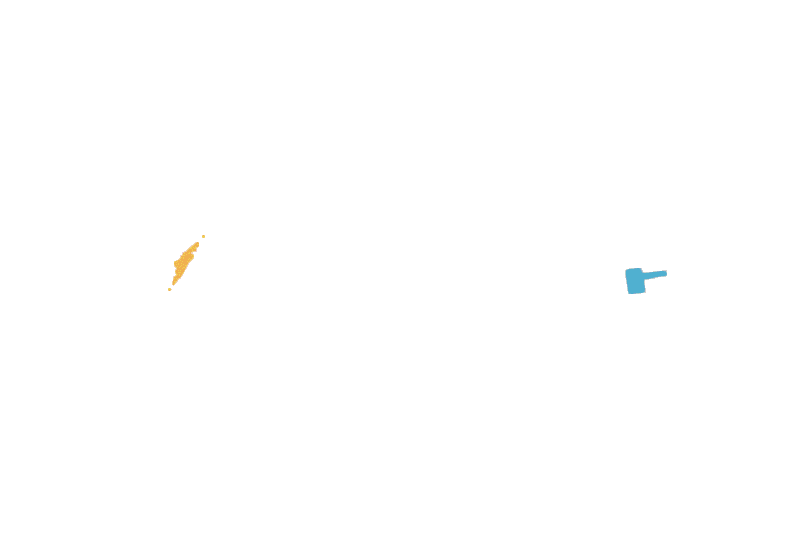

In [11]:
render_png([(uv["scan"], SCAN_RGB), (uv["model"], MODEL_RGB)], OUT / "uvigo_before.png", eye_dir=(0.3, -0.5, 1.0))

After, seed 0 (the table above):


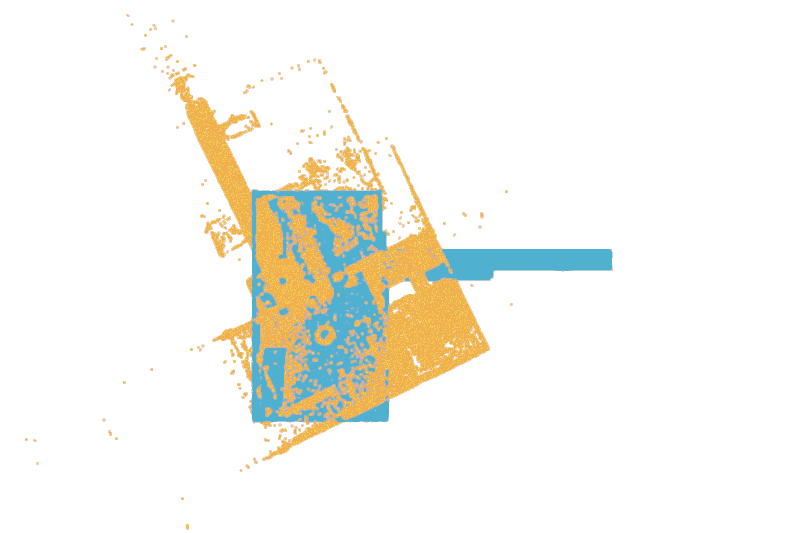

After, best of 5 seeds by ICP fitness (seed 3):


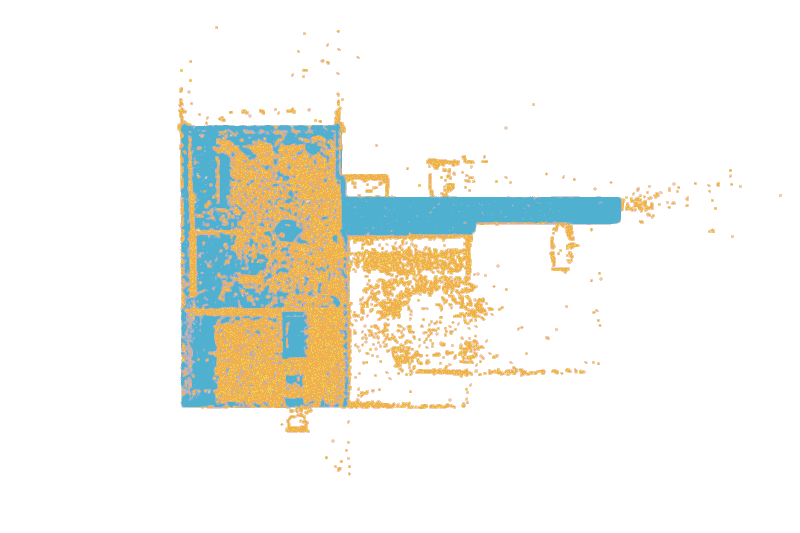

Ground truth T:


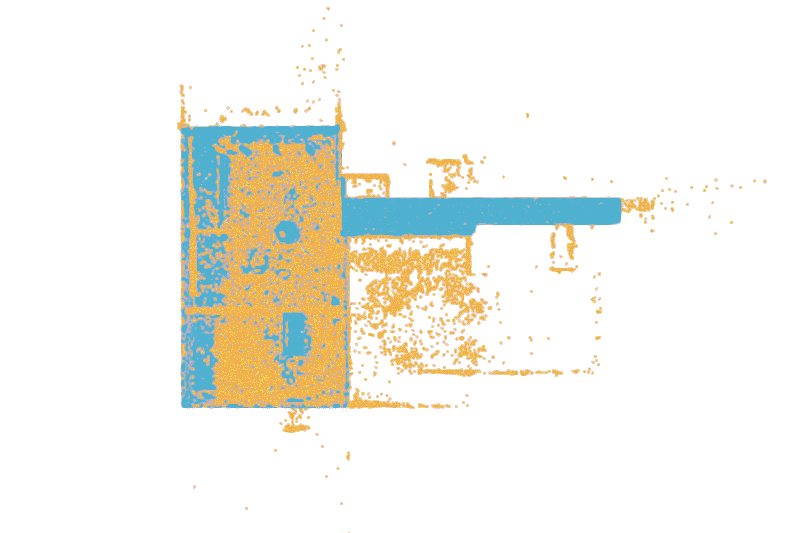

In [12]:
def moved(s, T):
    return o3d.geometry.PointCloud(s["scan"]).transform(T)

print(f"After, seed {SEED} (the table above):")
render_png([(moved(uv, T_icp), SCAN_RGB), (uv["model"], MODEL_RGB)], OUT / "uvigo_after.png", zmax=3.0)
print(f"After, best of {len(SEED_SWEEP)} seeds by ICP fitness (seed {best_seed}):")
render_png([(moved(uv, T_best), SCAN_RGB), (uv["model"], MODEL_RGB)], OUT / "uvigo_after_best.png", zmax=3.0)
print("Ground truth T:")
render_png([(moved(uv, uv["T_gt"]), SCAN_RGB), (uv["model"], MODEL_RGB)], OUT / "uvigo_ground_truth.png", zmax=3.0)

## The scaled sample (`fur_010-modelnet`)

Its ground truth has scale 1.357, so the scan is smaller than the model by that factor. First the same rigid pipeline,
unchanged.

In [13]:
fur = load_sample("fur_010")
voxel_f = VOXEL_FRACTION * fur["diag"]
print(f"model: {len(fur['mesh'].triangles):,} triangles, bbox {ext(fur['mesh'])}, diagonal {fur['diag']:.1f}; "
      f"scan: {len(fur['scan'].points):,} points, bbox {ext(fur['scan'])}")
print(f"ground truth: scale {scale_of(fur['T_gt']):.4f}; voxel {voxel_f:.3f} ({VOXEL_FRACTION} x diagonal)\n")
Tr_f, Ti_f, info_f = register(fur["scan"], fur["model"], voxel_f)
fur_rigid = [("RANSAC (rigid)", metrics(Tr_f, fur)), ("RANSAC + ICP (rigid)", metrics(Ti_f, fur)),
             ("ground truth T (reference)", metrics(fur["T_gt"], fur))]
table(fur_rigid)
print("\nRANSAC + ICP (rigid)", gate_line(fur_rigid[1][1], scaled=True))
# Known answer: the rigid baseline fails on the scaled sample (scale cannot be recovered; centroid far off).
assert fur_rigid[1][1]["scale_err"] > GATE_SCALE_REL, fur_rigid[1][1]
assert fur_rigid[1][1]["centroid_m"] > GATE_TRANS_M, fur_rigid[1][1]

model: 1,510 triangles, bbox [20.4 23.3 36.7], diagonal 48.0; scan: 32,793 points, bbox [26.5 24.1 19.4]
ground truth: scale 1.3573; voxel 0.384 (0.008 x diagonal)



                              rot err      |dt|  centroid  resid mean  resid med   scale scale err
                                (deg)       (m)   err (m)         (m)        (m)               (%)
RANSAC (rigid)                  6.584    49.148     3.122       1.050      0.454  1.0000     26.32
RANSAC + ICP (rigid)            1.906    46.166     2.648       0.923      0.186  1.0000     26.32
ground truth T (reference)      0.000     0.000     0.000       0.002      0.002  1.3573      0.00

RANSAC + ICP (rigid) vs the roadmap gate (a judgement call): rotation within 2.0 deg, centroid error outside 5 cm, scale error outside 1%


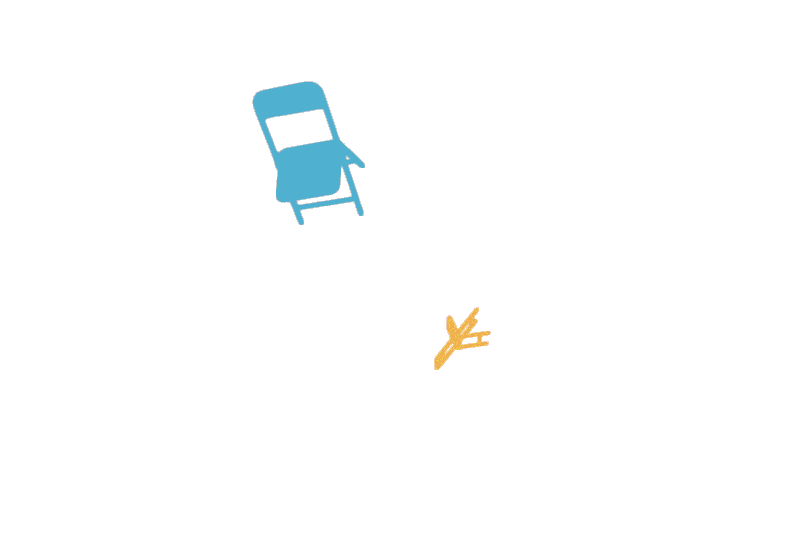

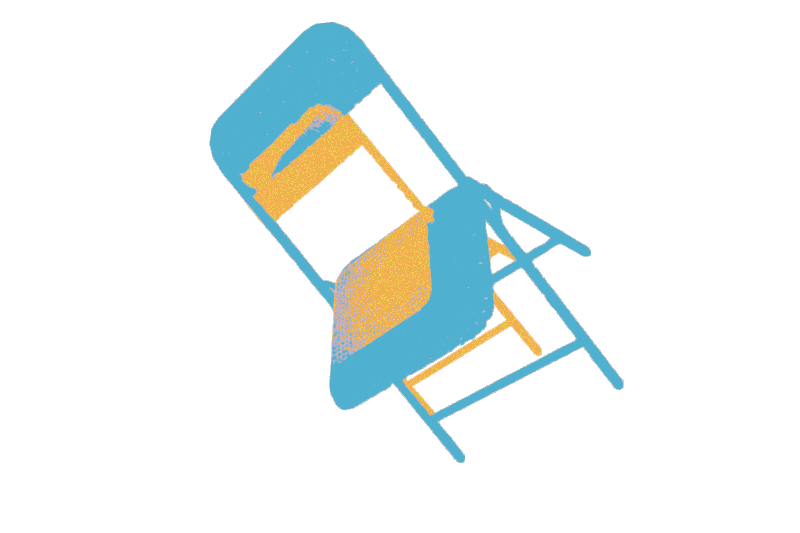

In [14]:
render_png([(fur["scan"], SCAN_RGB), (fur["model"], MODEL_RGB)], OUT / "fur010_before.png", eye_dir=(0.3, -0.5, 1.0))
render_png([(moved(fur, Ti_f), SCAN_RGB), (fur["model"], MODEL_RGB)], OUT / "fur010_rigid.png", eye_dir=(0.6, -0.8, 0.6))

### One cheap scale estimate

**Estimate.** Compare how spread out the two clouds are: `s = RMS radius of the model / RMS radius of the scan`, each
about its own centroid, on the voxel-downsampled clouds (the downsampling evens out density, which is far from uniform
in a scan). The scan is multiplied by `s`, the rigid pipeline reruns, and the transforms are composed:
`T = T_rigid · diag(s, s, s, 1)`.

**What it assumes.** Both clouds cover the same extent of the same object: every part of the model is in the scan and
nothing else is. The RMS radius then scales exactly with the object.

**Why that breaks on real indoor scans.** A scan has clutter (extra points, mostly near the centre), areas outside
the model (extra points far out), and gaps (occlusion, a single scanner position). Each of these changes the RMS radius
without any change of scale. The check on UVigo, where the true scale is 1, shows by how much.

In [15]:
def rms_radius(pcd, voxel):
    p = np.asarray(pcd.voxel_down_sample(voxel).points)
    return float(np.sqrt(((p - p.mean(0)) ** 2).sum(1).mean()))

s_fur = rms_radius(fur["model"], voxel_f) / rms_radius(fur["scan"], voxel_f)
s_uv = rms_radius(uv["model"], voxel) / rms_radius(uv["scan"], voxel)
print(f"fur_010 (scale {scale_of(fur['T_gt']):.4f}): estimated {s_fur:.4f}, scale error {100 * abs(s_fur - scale_of(fur['T_gt'])) / scale_of(fur['T_gt']):.2f}%")
print(f"UVigo   (scale {scale_of(uv['T_gt']):.4f}): estimated {s_uv:.4f}, scale error {100 * abs(s_uv - scale_of(uv['T_gt'])) / scale_of(uv['T_gt']):.2f}%")

S = np.diag([s_fur, s_fur, s_fur, 1.0])
scaled_scan = dict(fur, scan=o3d.geometry.PointCloud(fur["scan"]).transform(S))
Tr_s, Ti_s, _ = register(scaled_scan["scan"], fur["model"], voxel_f)
T_final_r, T_final = Tr_s @ S, Ti_s @ S          # compose: scale first, then the rigid transform
fur_scaled = [("scale + RANSAC", metrics(T_final_r, fur)), ("scale + RANSAC + ICP", metrics(T_final, fur)),
              ("ground truth T (reference)", metrics(fur["T_gt"], fur))]
print()
table(fur_scaled)
print("\nscale + RANSAC + ICP", gate_line(fur_scaled[1][1], scaled=True))
# Known answers: the RMS-radius estimate is within 5% of the true scale on fur_010 (2.2% now; 5% leaves margin for
# downsampling/seed changes) but still misses the 1% gate; with it the rigid pipeline lands inside the rotation and 5 cm gates.
assert abs(s_fur - scale_of(fur["T_gt"])) / scale_of(fur["T_gt"]) < 0.05, s_fur
assert fur_scaled[1][1]["scale_err"] > GATE_SCALE_REL, "scale error now inside 1%: update the Answer cell"
assert fur_scaled[1][1]["rot_deg"] <= GATE_ROT_DEG and fur_scaled[1][1]["centroid_m"] <= GATE_TRANS_M, fur_scaled[1][1]

fur_010 (scale 1.3573): estimated 1.3872, scale error 2.20%
UVigo   (scale 1.0000): estimated 0.8738, scale error 12.62%



                              rot err      |dt|  centroid  resid mean  resid med   scale scale err
                                (deg)       (m)   err (m)         (m)        (m)               (%)
scale + RANSAC                  1.738     7.077     0.206       0.181      0.146  1.3872      2.20
scale + RANSAC + ICP            0.125     4.085     0.033       0.094      0.042  1.3872      2.20
ground truth T (reference)      0.000     0.000     0.000       0.002      0.002  1.3573      0.00

scale + RANSAC + ICP vs the roadmap gate (a judgement call): rotation within 2.0 deg, centroid error within 5 cm, scale error outside 1%


In [16]:
print(f"fur_010 at voxel fraction {VOXEL_FRACTION}, seeds {SEED_SWEEP}: rotation error / centroid error after ICP")
for label, pre in [("rigid", None), ("scale estimate + rigid", S)]:
    out = []
    for sd in SEED_SWEEP:
        src = fur["scan"] if pre is None else scaled_scan["scan"]
        _, Ti, _ = register(src, fur["model"], voxel_f, seed=sd)
        T_all = Ti if pre is None else Ti @ pre
        out.append(f"{rotation_error_deg(T_all, fur['T_gt']):5.2f} d / {centroid_error(T_all, fur):6.3f} m")
    print(f"  {label:24s}" + "   ".join(out))

fur_010 at voxel fraction 0.008, seeds [0, 1, 2, 3, 4]: rotation error / centroid error after ICP


  rigid                    1.91 d /  2.648 m    1.91 d /  2.648 m    1.91 d /  2.648 m    1.91 d /  2.648 m    1.90 d /  2.648 m


  scale estimate + rigid   0.13 d /  0.033 m    0.13 d /  0.033 m    0.13 d /  0.033 m    0.13 d /  0.033 m    0.13 d /  0.033 m


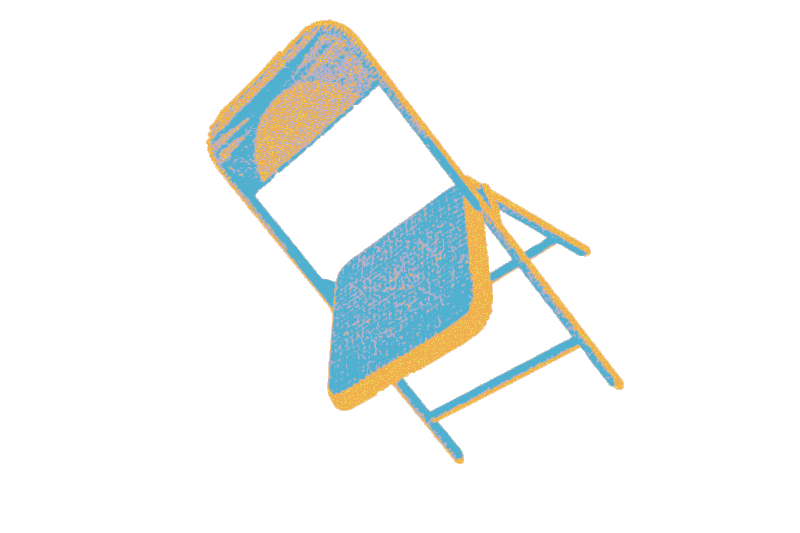

In [17]:
render_png([(moved(fur, T_final), SCAN_RGB), (fur["model"], MODEL_RGB)], OUT / "fur010_scaled.png", eye_dir=(0.6, -0.8, 0.6))

### Alternatives to the RMS-radius estimate

- **Scale-aware ICP**: `TransformationEstimationPointToPoint(with_scaling=True)` estimates a uniform scale inside every
  ICP iteration. It needs a start that is already roughly right (so it does not remove the global step) and the same
  coverage assumption does not apply, because only matched points count. Open3D's point-to-plane estimator has no scaling.
- **Scale-invariant features or matching**: normalise each local patch by its own size (multi-scale or scale-adaptive
  descriptors), or match in a space where scale drops out, so the global step finds the scale together with the pose.
- **Prior knowledge**: for real scans taken in metres the scale is 1 by construction. Only the benchmark's synthetic scaling
  creates the problem, so how much Phase 1 needs this depends on whether the target data is ever off-scale.

## Run summary

In [18]:
print(f"notebook wall time {time.perf_counter() - t_notebook:.0f} s; in-kernel peak RSS {peak_rss_gb():.2f} GB")
for f in sorted(OUT.glob("*.png")):
    print(f"{f.name:24s}{f.stat().st_size / 1024:7.0f} KB")

notebook wall time 58 s; in-kernel peak RSS 1.07 GB
fur010_before.png             6 KB
fur010_rigid.png             28 KB
fur010_scaled.png            48 KB
uvigo_after.png              41 KB
uvigo_after_best.png         54 KB
uvigo_before.png              3 KB
uvigo_ground_truth.png       56 KB


## Answer

Numbers below are from this notebook's run (seed 0 unless a seed is named). The parameters were chosen after seeing
UVigo's ground truth, so they are optimistic, and each sample is one sample.

**Does the baseline work?** Only on some draws, and nothing in the pipeline says which.

- On UVigo (scale 1) the pipeline can recover `T`. The best draw (seed 3 at voxel fraction 0.008, about 0.39 m) has a
  rotation error of 0.34 degrees and a registration residual of 0.046 m median, against 0.042 m under `T` itself.
  Its centroid error is 0.14 m, which is outside the 5 cm gate; the translation-vector error is 1.4 m, mostly a rotation
  error multiplied by the scan's distance from its own origin.
- RANSAC is a lottery on this room. At voxel fraction 0.008, 2 of 5 seeds succeed; at 0.006, 0 of 5; at 0.012, 2 of 5. The
  failures are mostly about 180 degrees off (a long rectangular room looks alike from both ends), and ICP does not repair
  them. The seed declared in advance (0) is one of the failures: 115.7 degrees after ICP, residual median 0.73 m.
- Taking the draw with the highest ICP fitness picked a correct draw at 0.008 and at 0.012 and a wrong one at 0.006.
  That rule needs no ground truth, but three voxel sizes on one sample do not make it a result.

**What does Phase 1 need for scale?**

- Scale cannot be left out. On `fur_010` (scale 1.357) the rigid pipeline recovers the rotation (1.9 degrees) but
  leaves a residual median of 0.186 m, against 0.002 m under `T`, and the scan centroid 2.6 m off. 71 of the 137 samples
  are scaled, from 0.69 to 1.98.
- The RMS-radius estimate gave 1.387 for a true 1.357 (2.2% error, outside the 1% gate). With it, the rigid pipeline got
  0.13 degrees, 0.033 m centroid error and a residual median of 0.042 m on all five seeds. It worked here because
  the scan is a complete, clutter-free copy of the model; on UVigo, where the scale is 1, the same estimate gives 0.874
  (12.6% error). Real scans, and the real indoor samples among the scaled ones, will not meet its assumption.
- So Phase 1 should estimate scale from the registration itself: start from the RMS-radius value only as an
  initial guess, refine with scale-aware ICP (`with_scaling=True`) and check whether that gets below 1%, and try
  scale-invariant features for the global step. Scaled samples are reported separately.
- Also for Phase 1: several RANSAC restarts with a selection rule that does not use the ground truth, and a finer-voxel ICP stage,
  since the 5 cm gate needs more than a 0.39 m voxel gives. Neither is tested here.